# Stat 220 Midterm B: the take-home analysis
## Turnaround time at a bicycle repair shop

A repair shop switched to a new parts supplier for some jobs this year. The owner compared average turnaround before and after, saw no real difference, and is about to go back to the old supplier. They have asked you to check.

**100 points in all.** Run the setup cell first. Put your work in the cell under each task and your written answer in the markdown cell that follows it. Several tasks build on an earlier one, so work them in order.

---

**Getting help.** You may use AI, and you may ask the TAs, the professor, and each other. Two limits on the AI:

- Do not paste the whole notebook into it.
- Do not give it an entire task prompt and ask for the answer. If a prompt is unclear, you can paste a whole task prompt in to help clarify.

Everything else is open. Use the generate function in Colab or your editor to help write the code, ask about a specific piece of output, or have a piece of your work checked.

Use the methods from this course. A technique we have not covered is a sign that the AI has been asked for the answer rather than for help.

Add text or code boxes as needed, but do not change or modify the numbering of the tasks.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import train_test_split

repairs = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/repair_jobs.csv")
repairs.head()

,days,parts_needed,parts_cost,tech_years,bike_type,new_supplier,ticket_number,shop_rating,quarter
0,4.32,5,86.03,1,mountain,0,2833,2,2
1,1.24,1,21.65,1,electric,0,2590,2,2
2,8.57,5,99.39,2,electric,1,5472,1,2
3,1.23,0,0.00,5,road,0,6510,5,3
4,0.72,2,38.79,2,commuter,0,3206,2,3


### Task 1.  (6 points)

Before you fit anything, decide what kind of model this question calls for. Name the family, say why it suits this outcome, and say what you need back from it that a random forest could not give you.

_Your answer:_ For this question we should use a linear regression model comparing the turnaround time for the two suppliers while accounting for other factors that may be influencing turnaround time for one supplier or the other. Regression models are simpler models and tend to operate well with continuous variables, which turnaround time is. I would need to see the coefficient for supplier while holding other factors constant. I would also like to see the standard errors and confidence intervals that a linear regression model would produce. Random forests are not capable of producing any of these.



### Task 2.  (8 points)

Make two plots that could be helpful concerning the shop's question. Then, in two or three sentences, say if there is anything notable you see that may affect modeling choices.

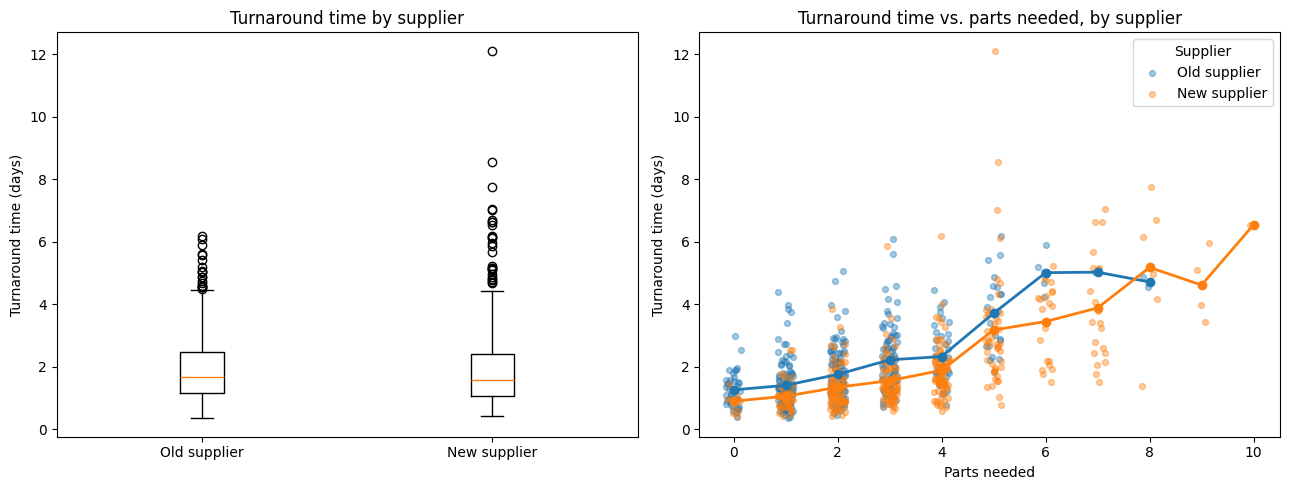

              count  mean   std   min   25%   50%   75%    max
new_supplier                                                  
New supplier  399.0  2.02  1.46  0.42  1.06  1.57  2.42  12.12
Old supplier  401.0  1.94  1.14  0.35  1.15  1.66  2.48   6.18


In [3]:
# Task 2: exploratory plots
supplier_labels = repairs["new_supplier"].map({0: "Old supplier", 1: "New supplier"})
rng = np.random.default_rng(220)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: side-by-side boxplots of turnaround time by supplier
old_days = repairs.loc[repairs["new_supplier"] == 0, "days"]
new_days = repairs.loc[repairs["new_supplier"] == 1, "days"]
axes[0].boxplot([old_days, new_days])
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels(["Old supplier", "New supplier"])
axes[0].set_ylabel("Turnaround time (days)")
axes[0].set_title("Turnaround time by supplier")

# Plot 2: turnaround time vs. parts needed, colored by supplier
for flag, label, color in [(0, "Old supplier", "tab:blue"), (1, "New supplier", "tab:orange")]:
    sub = repairs[repairs["new_supplier"] == flag]
    # small horizontal jitter so points at the same parts count don't stack
    x = sub["parts_needed"] + rng.uniform(-0.15, 0.15, len(sub))
    axes[1].scatter(x, sub["days"], alpha=0.4, s=18, color=color, label=label)
    # average days at each parts count, per supplier
    means = sub.groupby("parts_needed")["days"].mean()
    axes[1].plot(means.index, means.values, color=color, linewidth=2, marker="o")
axes[1].set_xlabel("Parts needed")
axes[1].set_ylabel("Turnaround time (days)")
axes[1].set_title("Turnaround time vs. parts needed, by supplier")
axes[1].legend(title="Supplier")

plt.tight_layout()
plt.show()

# Numbers behind the boxplot
print(repairs.groupby(supplier_labels)["days"].describe().round(2))


_Your answer:_ The first plot that I thought could be helpful was a side by side boxplot to get a sense of the shape and spread of turnaround times for each supplier. Once I saw that I decided I wanted to add some color to the data and picked my second plot which compares the turnaround time by the number of parts needed by each supplier which allows us to get a more direct comparison between performance for the two.

A couple of things to note: first, the new supplier does appear to have a greater skew towards longer turnaround times, but second, it seems like it actually has a lower turnaround time on average for the number of parts needed than the old supplier. The new supplier just seems to have more jobs with a higher parts count, so we will need to control for that in our model. There are also a few outliers in the data for the new supplier at 5 parts that we might want to adjust for in our model, that combined with the skew means we may need to do a log transformation.



### Task 3.  (10 points)

The owner compared average repair time under the old and the new supplier, saw almost no difference, and is ready to drop the new one. Perform a formal statistical test for that comparison. Report both averages, the difference, a test, and a 95% interval, then say in two or three sentences what it does and does not establish.

In [4]:
# Task 3: two-sample t-test comparing average turnaround by supplier
old_days = repairs.loc[repairs["new_supplier"] == 0, "days"]
new_days = repairs.loc[repairs["new_supplier"] == 1, "days"]

mean_old = old_days.mean()
mean_new = new_days.mean()
diff = mean_new - mean_old   # new minus old

# Welch two-sample t-test (does not assume equal variances)
t_res = stats.ttest_ind(new_days, old_days, equal_var=False)

# 95% confidence interval for the difference in means (Welch)
v_new = new_days.var(ddof=1) / len(new_days)
v_old = old_days.var(ddof=1) / len(old_days)
se_diff = np.sqrt(v_new + v_old)
df = (v_new + v_old)**2 / (v_new**2 / (len(new_days) - 1) + v_old**2 / (len(old_days) - 1))
t_crit = stats.t.ppf(0.975, df)
ci_low, ci_high = diff - t_crit * se_diff, diff + t_crit * se_diff

print(f"Old supplier: n = {len(old_days)}, mean = {mean_old:.3f} days")
print(f"New supplier: n = {len(new_days)}, mean = {mean_new:.3f} days")
print(f"Difference (new - old): {diff:.3f} days")
print(f"Welch t = {t_res.statistic:.3f}, df = {df:.1f}, p-value = {t_res.pvalue:.4f}")
print(f"95% CI for difference: ({ci_low:.3f}, {ci_high:.3f}) days")


Old supplier: n = 401, mean = 1.937 days
New supplier: n = 399, mean = 2.016 days
Difference (new - old): 0.079 days
Welch t = 0.852, df = 750.5, p-value = 0.3947
95% CI for difference: (-0.103, 0.260) days


_Your answer:_ In comparing the average repair time for both the old and new supplier, we learn that the old supplier had an average of 1.937 days while the new supplier had an average repair time of 2.016 days. That provides us with a 0.079 day difference (95% CI: -0.103, 0.260). Our test statistic was 0.852(Welch t). While it appears that the average time for repairs is higher for the new supplier than the old supplier, it does not control for other variables that may impact average time, nor does it provide us with much confidence that there is a significant difference between the two as the confidence interval includes 0 (p-value = 0.39).



### Task 4.  (8 points)

Now fit a model for repair time that includes the supplier indicator along with `parts_needed`, `tech_years` and `bike_type`. Report the supplier coefficient with its interval, interpret it in a sentence that names what is held fixed, and explain in two or three sentences why it differs from Task 3.

In [5]:
# Task 4: multiple regression for repair time
model4 = smf.ols("days ~ new_supplier + parts_needed + tech_years + C(bike_type)", data=repairs).fit()
print(model4.summary())

# Supplier coefficient and its 95% confidence interval
b_sup = model4.params["new_supplier"]
ci_sup = model4.conf_int().loc["new_supplier"]
print()
print(f"Supplier coefficient: {b_sup:.3f} days")
print(f"95% CI: ({ci_sup[0]:.3f}, {ci_sup[1]:.3f}) days")
print(f"p-value: {model4.pvalues['new_supplier']:.4g}")


                            OLS Regression Results                            
Dep. Variable:                   days   R-squared:                       0.455
Model:                            OLS   Adj. R-squared:                  0.451
Method:                 Least Squares   F-statistic:                     110.2
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          5.96e-101
Time:                        16:47:05   Log-Likelihood:                -1106.7
No. Observations:                 800   AIC:                             2227.
Df Residuals:                     793   BIC:                             2260.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

_Your answer:_ The new supplier is expected to take 0.428 fewer days (new supplier coefficient = -0.428) than the old supplier (95% CI = -0.573, -0.282), holding all other factors fixed (parts needed, technician experience, and bike type). These results differ from what we learned in task 3 because before we had only tested for the average repair time for each supplier without controlling for other predictors. However, in this model we isolated the effects of each of these variables and are able to see the real difference in supplier performance (speed) independent of the other variables. In this case, the variable that appears to be increasing time is actually the parts needed variable. What before might have persuaded our client to withdraw from business with the new supplier would now encourage them to consider the new supplier over the old supplier from an efficiency standpoint.



### Task 5.  (6 points)

Add `parts_cost` to the model from Task 4. Report the coefficient on `parts_needed` and its standard error before and after. Look at the p-value on `parts_cost` as well as the p-value on `parts_needed` before and after `parts_cost` was added. Explain in two or three sentences what is going on.

In [6]:
# Task 5: add parts_cost to the Task 4 model
model5 = smf.ols("days ~ new_supplier + parts_needed + tech_years + C(bike_type) + parts_cost", data=repairs).fit()
print(model5.summary())

# parts_needed before (Task 4) and after (Task 5) adding parts_cost
compare = pd.DataFrame({
    "coef": [model4.params["parts_needed"], model5.params["parts_needed"]],
    "std err": [model4.bse["parts_needed"], model5.bse["parts_needed"]],
    "p-value": [model4.pvalues["parts_needed"], model5.pvalues["parts_needed"]],
}, index=["Before (Task 4)", "After (+ parts_cost)"])
print()
print("parts_needed:")
print(compare.round(8))

print()
print(f"parts_cost: coef = {model5.params['parts_cost']:.4f}, "
      f"std err = {model5.bse['parts_cost']:.4f}, p-value = {model5.pvalues['parts_cost']:.4g}")

# How closely parts_cost tracks parts_needed
print(f"Correlation between parts_needed and parts_cost: {repairs['parts_needed'].corr(repairs['parts_cost']):.3f}")


                            OLS Regression Results                            
Dep. Variable:                   days   R-squared:                       0.455
Model:                            OLS   Adj. R-squared:                  0.450
Method:                 Least Squares   F-statistic:                     94.39
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          6.24e-100
Time:                        16:47:05   Log-Likelihood:                -1106.6
No. Observations:                 800   AIC:                             2229.
Df Residuals:                     792   BIC:                             2267.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

_Your answer:_ After adding the parts cost variable we see that the coefficient on parts needed drops from 0.467 to 0.435 and standard error increases from 0.020 to 0.105. We assume significance for parts needed both before and after adding in parts cost (both p-values < 0.0001). However, we do not have the data to support that parts cost is significant (p-value = 0.7607).In this case there is a strong correlation between parts needed and parts cost variables (correlation = 0.983) so although the parts needed coefficient has been watered down slightly, errors have increased because the two predictors account for the same effect.



### Task 6.  (6 points)

Bike type has four levels. Report its coefficients, say which level is the baseline and how you can tell, and write the sentence that interprets one of the others. Say what would change if a different level were the baseline.

In [7]:
# Task 6: bike type levels in the data (alphabetical order; the first is the default baseline)
print(repairs["bike_type"].value_counts().sort_index())


bike_type
commuter    332
electric    117
mountain    159
road        192
Name: count, dtype: int64


_Your answer:_ In the task 4 model, there are four levels of bike type: electric (coefficient = 0.746), mountain (coefficient = 0.1471), road (coefficient = -0.0979), and commuter (intercept = 0.9920) with commuter being the baseline (it is the one not listed in the regression table). From this information we can assume that an electric bike would take 0.746 days longer to repair than a commuter bike, holding all else fixed (supplier, parts needed, and technician experience). If we were to change the baseline to be a different bike, then the other bike coefficients would adjust to reflect their relation to the new baseline.



### Task 7.  (8 points)

Plot the residuals of the Task 4 model against its fitted values. Name what you see, and back it with a number: report the standard deviation of the residuals on the upper half of the fitted values divided by the standard deviation on the lower half. Say what this does to the intervals you reported in Task 4.

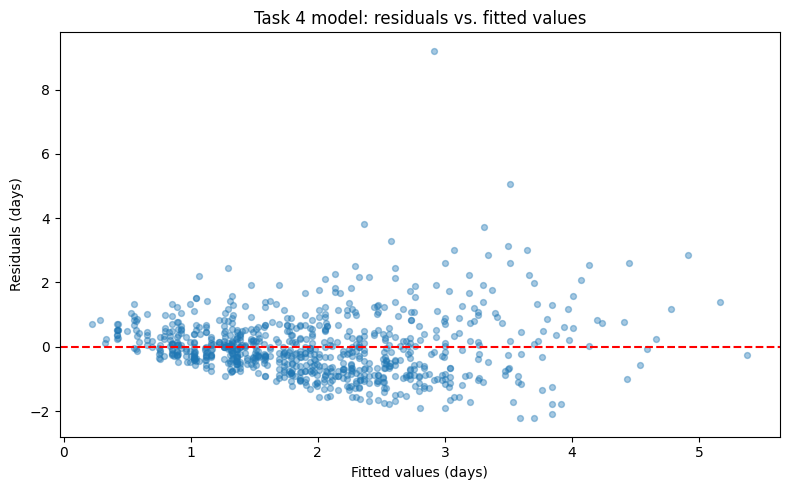

Median fitted value: 1.898
SD of residuals, upper half: 1.233
SD of residuals, lower half: 0.591
Spread ratio (upper / lower): 2.086


In [8]:
# Task 7: residuals vs. fitted values for the Task 4 model
fitted4 = model4.fittedvalues
resid4 = model4.resid

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted4, resid4, alpha=0.4, s=18)
ax.axhline(0, color="red", linestyle="--")
ax.set_xlabel("Fitted values (days)")
ax.set_ylabel("Residuals (days)")
ax.set_title("Task 4 model: residuals vs. fitted values")
plt.tight_layout()
plt.show()

# Spread ratio: SD of residuals on the upper half of fitted values / SD on the lower half
median_fit = fitted4.median()
sd_upper = resid4[fitted4 > median_fit].std()
sd_lower = resid4[fitted4 <= median_fit].std()
print(f"Median fitted value: {median_fit:.3f}")
print(f"SD of residuals, upper half: {sd_upper:.3f}")
print(f"SD of residuals, lower half: {sd_lower:.3f}")
print(f"Spread ratio (upper / lower): {sd_upper / sd_lower:.3f}")


_Your answer:_ The residuals have a distinct shape being closer on the left side of the chart (SD of residuals = 0.591) and more spread on the right side (SD of residuals = 1.233). The spread ratio between standard deviations is 2.086. Because the spread ratio is large, we have to question our confidence interval for task 4 (95% CI:-0.573, -0.282) as it may not be accurate. One spread does not appear to describe all jobs. Given the shape of our residuals we should consider running a log transformation.



### Task 8.  (10 points)

Fit the model again with the log of repair days as the outcome. Report the same spread ratio for the new residuals, say which model you would use and why, and write the sentence that interprets the supplier coefficient on the log scale. A coefficient of $b$ on a logged outcome is roughly a $100(e^{b}-1)%$ change.

Smallest repair time: 0.35 days (must be > 0 to take logs)
                            OLS Regression Results                            
Dep. Variable:               log_days   R-squared:                       0.469
Model:                            OLS   Adj. R-squared:                  0.465
Method:                 Least Squares   F-statistic:                     116.7
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          1.71e-105
Time:                        17:16:52   Log-Likelihood:                -459.79
No. Observations:                 800   AIC:                             933.6
Df Residuals:                     793   BIC:                             966.4
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------

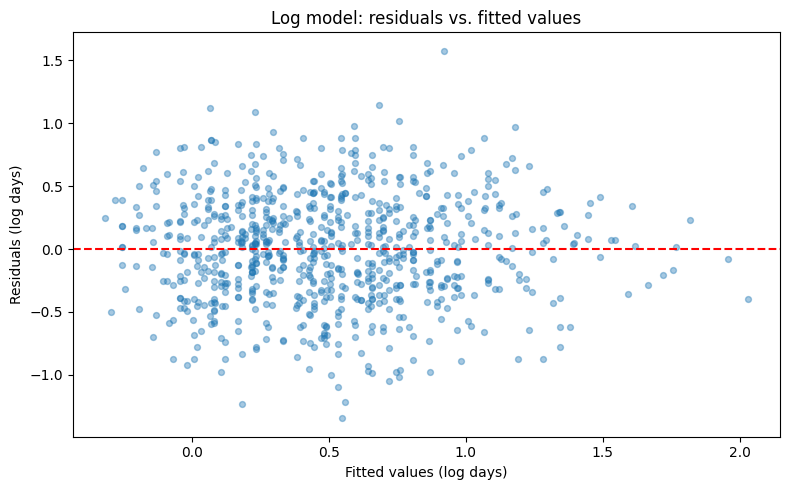

SD of residuals, upper half: 0.451
SD of residuals, lower half: 0.410
Spread ratio (upper / lower): 1.098   (Task 4 model: 2.086)

Supplier coefficient (log scale): -0.2261, 95% CI (-0.2907, -0.1614)
As % change in repair time: -20.2%, 95% CI (-25.2%, -14.9%)


In [9]:
# Task 8: same model as Task 4, with log(days) as the outcome
print(f"Smallest repair time: {repairs['days'].min()} days (must be > 0 to take logs)")
repairs["log_days"] = np.log(repairs["days"])

model8 = smf.ols("log_days ~ new_supplier + parts_needed + tech_years + C(bike_type)", data=repairs).fit()
print(model8.summary())

# Residuals vs. fitted for the log model
fitted8 = model8.fittedvalues
resid8 = model8.resid
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted8, resid8, alpha=0.4, s=18)
ax.axhline(0, color="red", linestyle="--")
ax.set_xlabel("Fitted values (log days)")
ax.set_ylabel("Residuals (log days)")
ax.set_title("Log model: residuals vs. fitted values")
plt.tight_layout()
plt.show()

# Same spread ratio as Task 7
median_fit8 = fitted8.median()
sd_upper8 = resid8[fitted8 > median_fit8].std()
sd_lower8 = resid8[fitted8 <= median_fit8].std()
print(f"SD of residuals, upper half: {sd_upper8:.3f}")
print(f"SD of residuals, lower half: {sd_lower8:.3f}")
print(f"Spread ratio (upper / lower): {sd_upper8 / sd_lower8:.3f}   (Task 4 model: {sd_upper / sd_lower:.3f})")

# Supplier coefficient on the log scale and as an approximate % change
b8 = model8.params["new_supplier"]
ci8 = model8.conf_int().loc["new_supplier"]
print()
print(f"Supplier coefficient (log scale): {b8:.4f}, 95% CI ({ci8[0]:.4f}, {ci8[1]:.4f})")
print(f"As % change in repair time: {100*(np.exp(b8)-1):.1f}%, "
      f"95% CI ({100*(np.exp(ci8[0])-1):.1f}%, {100*(np.exp(ci8[1])-1):.1f}%)")


_Your answer:_ Using a log of repair days, we see a much more even spread of residuals across both upper (SD of residuals = 0.451) and lower halves (SD of residuals = 0.410). Our spread ratio is now 1.098 which is near 1 (even), so we would want to use the log model as it can be applied to all of our current data. Using the log scale, we now assume that with all over variables held constant (bike type, technicain experiene, etc.), the new supplier would have about a 20.2% shorter turnaround time (95% CI: -14.9%, -25.2%) for repairs than the old supplier (supplier coefficient = -0.2261; 95% CI: -0.2907, -0.1614).



### Task 9.  (8 points)

Fit a model for log repair days that starts with every predictor the shop records. Then cut it down to the columns that are carrying their weight, using a method from this course. Say which method you used, report what it kept and what it dropped, and say in two or three sentences whether the result changes anything about your answer to Task 4.

In [10]:
# Task 9: full model for log(days), then backward stepwise selection by AIC
# Every predictor the shop records (days / log_days are the outcome, so they are left out)
all_terms = ["new_supplier", "parts_needed", "parts_cost", "tech_years", "C(bike_type)",
             "ticket_number", "shop_rating", "C(quarter)"]

def fit_terms(terms):
    return smf.ols("log_days ~ " + " + ".join(terms), data=repairs).fit()

full_model = fit_terms(all_terms)
print(full_model.summary())

criterion = "aic"   # change to "bic" to run the same procedure by BIC

current = list(all_terms)
current_score = getattr(fit_terms(current), criterion)
print(f"\nStarting {criterion.upper()} (all predictors): {current_score:.2f}")

while len(current) > 1:
    # Try dropping each remaining term one at a time
    scores = {t: getattr(fit_terms([x for x in current if x != t]), criterion) for t in current}
    best_drop = min(scores, key=scores.get)
    if scores[best_drop] < current_score:
        print(f"Drop {best_drop:<15} -> {criterion.upper()} {current_score:.2f} to {scores[best_drop]:.2f}")
        current.remove(best_drop)
        current_score = scores[best_drop]
    else:
        print(f"No single drop lowers {criterion.upper()} further; stopping.")
        break

kept = current
dropped = [t for t in all_terms if t not in kept]
print(f"\nKept:    {kept}")
print(f"Dropped: {dropped}")

model9 = fit_terms(kept)
print()
print(model9.summary())

b9 = model9.params["new_supplier"]
ci9 = model9.conf_int().loc["new_supplier"]
print(f"\nSupplier coefficient (selected model): {b9:.4f}, 95% CI ({ci9[0]:.4f}, {ci9[1]:.4f})")
print(f"As % change: {100*(np.exp(b9)-1):.1f}%, 95% CI ({100*(np.exp(ci9[0])-1):.1f}%, {100*(np.exp(ci9[1])-1):.1f}%)")


                            OLS Regression Results                            
Dep. Variable:               log_days   R-squared:                       0.475
Model:                            OLS   Adj. R-squared:                  0.467
Method:                 Least Squares   F-statistic:                     59.25
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          2.03e-101
Time:                        17:30:23   Log-Likelihood:                -455.57
No. Observations:                 800   AIC:                             937.1
Df Residuals:                     787   BIC:                             998.0
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

_Your answer:_ To isolate the most appropriate predictors I used all variables and then ran a backwards stepwise approach against AIC. This removed parts cost, shop rating, and quarter, and retained new supplier, parts needed, tech years, bike type, and ticket number (AIC  937.1 -> 932.9). Using this model, our supplier coefficient is similar to the log of the task 4 model (task 8 coefficient = -0.2261), but decreases even further, becoming about 20.5% faster (coefficient = -0.2295, 95% CI: -0.2942, -0.1648). In this case, the retained ticket number variable is kept weakly and BIC gets worse with it in the model, so we would probably stick with the simpler model from task 8. My answer to task 4 remains the same that the new supplier is faster if we account for relevant variables.



### Task 10.  (8 points)

Fit a decision tree for log repair days from parts needed, technician experience, bike type and supplier. Choose its depth with an appropriate method and say why that method works. For this tree, state how many different exact values can be predicted.

 depth  train_MSE  test_MSE
     1     0.2363    0.2922
     2     0.2102    0.2600
     3     0.1935    0.2447
     4     0.1800    0.2299
     5     0.1660    0.2319
     6     0.1458    0.2563
     7     0.1325    0.2697
     8     0.1230    0.2868
     9     0.1173    0.3025
    10     0.1124    0.3093

Depth with lowest test MSE: 4


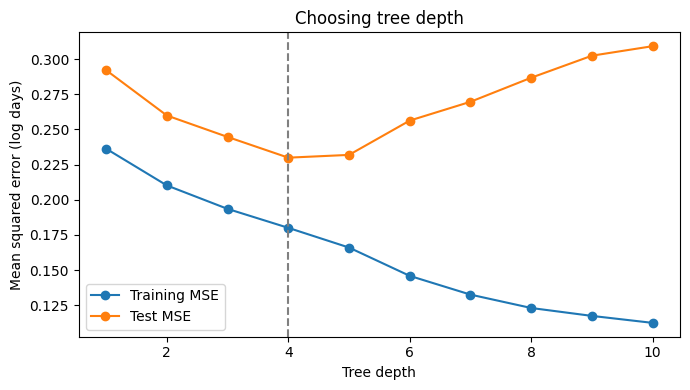

|--- parts_needed <= 4.500
|   |--- parts_needed <= 2.500
|   |   |--- tech_years <= 1.500
|   |   |   |--- bike_type_electric <= 0.500
|   |   |   |   |--- value: [0.354]
|   |   |   |--- bike_type_electric >  0.500
|   |   |   |   |--- value: [0.773]
|   |   |--- tech_years >  1.500
|   |   |   |--- tech_years <= 7.000
|   |   |   |   |--- value: [0.203]
|   |   |   |--- tech_years >  7.000
|   |   |   |   |--- value: [-0.020]
|   |--- parts_needed >  2.500
|   |   |--- bike_type_electric <= 0.500
|   |   |   |--- new_supplier <= 0.500
|   |   |   |   |--- value: [0.645]
|   |   |   |--- new_supplier >  0.500
|   |   |   |   |--- value: [0.423]
|   |   |--- bike_type_electric >  0.500
|   |   |   |--- tech_years <= 3.500
|   |   |   |   |--- value: [0.973]
|   |   |   |--- tech_years >  3.500
|   |   |   |   |--- value: [0.692]
|--- parts_needed >  4.500
|   |--- bike_type_electric <= 0.500
|   |   |--- parts_needed <= 5.500
|   |   |   |--- new_supplier <= 0.500
|   |   |   |   |---

In [11]:
# Task 10: regression tree for log(days), depth chosen with a train/test split
X = pd.get_dummies(repairs[["parts_needed", "tech_years", "bike_type", "new_supplier"]],
                   columns=["bike_type"], dtype=int)
y = repairs["log_days"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=220)

# Fit trees of increasing depth; score each on data it did NOT see during fitting
results = []
for d in range(1, 11):
    tree = DecisionTreeRegressor(max_depth=d, random_state=220).fit(X_train, y_train)
    train_mse = np.mean((tree.predict(X_train) - y_train) ** 2)
    test_mse = np.mean((tree.predict(X_test) - y_test) ** 2)
    results.append({"depth": d, "train_MSE": train_mse, "test_MSE": test_mse})
results = pd.DataFrame(results)
print(results.round(4).to_string(index=False))

best_depth = int(results.loc[results["test_MSE"].idxmin(), "depth"])
print(f"\nDepth with lowest test MSE: {best_depth}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(results["depth"], results["train_MSE"], marker="o", label="Training MSE")
ax.plot(results["depth"], results["test_MSE"], marker="o", label="Test MSE")
ax.axvline(best_depth, color="gray", linestyle="--")
ax.set_xlabel("Tree depth")
ax.set_ylabel("Mean squared error (log days)")
ax.set_title("Choosing tree depth")
ax.legend()
plt.tight_layout()
plt.show()

# Final tree at the chosen depth
tree10 = DecisionTreeRegressor(max_depth=best_depth, random_state=220).fit(X_train, y_train)
print(export_text(tree10, feature_names=list(X.columns), decimals=3))

# Number of distinct values the tree can predict = number of leaves
print(f"Number of leaves (distinct predicted values): {tree10.get_n_leaves()}")


_Your answer:_ The best depth for this tree is 4 which we determine by examining the MSE for the trained and untrained data. As expected MSE for trained data continues to drop with each added level of depth because the model starts accounting for peculiarities specific to the data set it is being trained on, but the untrained data drops until level 4 and then begins to increase again. At a depth of four, the expected predicted values we would see is 16 (leaves), but one branch stops early so we have 15 exact predicted values.



### Task 11.  (10 points)

Use the regression tree as a guide to recommend at least two new terms to add to the regression model from Task 8 that induce non-linearity. For each new term, check whether it improves the model or not.

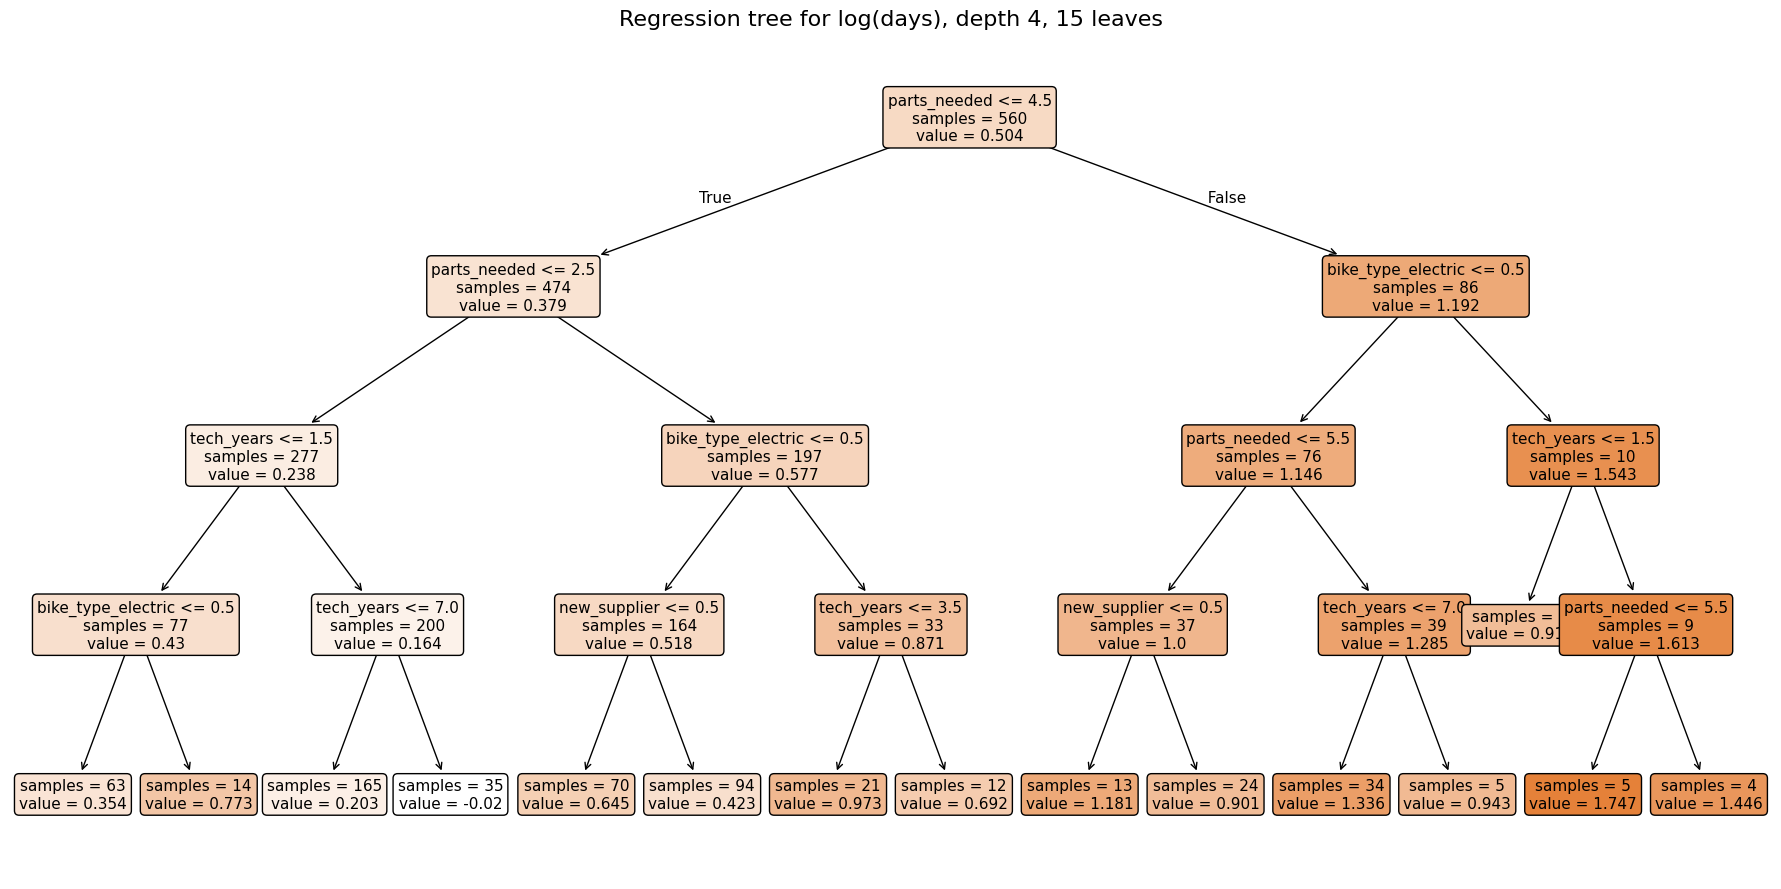

                             term coef  term p-value  adj R2       AIC       BIC
model                                                                           
Task 8 (no interactions)           NaN           NaN  0.4650  933.5888  966.3811
+ parts_needed x electric       0.0129        0.5996  0.4645  935.3103  972.7872
+ parts_needed x tech_years     0.0042        0.2053  0.4654  933.9672  971.4441
+ tech_years x electric        -0.0015        0.9246  0.4643  935.5798  973.0567
+ all three                        NaN           NaN  0.4642  937.7403  984.5864

Interaction terms when all three are in the model together:
                           coef  std err  p-value
parts_needed:electric    0.0112   0.0246   0.6490
parts_needed:tech_years  0.0042   0.0033   0.2142
tech_years:electric     -0.0018   0.0153   0.9070

Squared term added to the Task 8 model:
  coef = 0.0034, std err = 0.0033, p-value = 0.3014
  parts_needed (linear) coef = 0.1881, p-value = 1.814e-13
  adj R2: 0.4650 -> 

In [15]:
# Task 11: diagram of the Task 10 tree (boxes and arrows)
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(
    tree10,
    feature_names=list(X.columns),
    filled=True,          # shade boxes by predicted value (darker = longer repair)
    rounded=True,
    impurity=False,       # hide squared error to keep boxes readable
    precision=3,
    fontsize=11,
    ax=ax,
)
ax.set_title(f"Regression tree for log(days), depth {tree10.get_depth()}, {tree10.get_n_leaves()} leaves", fontsize=16)
plt.tight_layout()
plt.show()

# ---- Testing interaction terms suggested by the tree ----
# Indicator for electric bikes (1 = electric, 0 = any other type)
repairs["electric"] = (repairs["bike_type"] == "electric").astype(int)

base_formula = "log_days ~ new_supplier + parts_needed + tech_years + C(bike_type)"   # Task 8 model
new_terms = {
    "parts_needed x electric": "parts_needed:electric",
    "parts_needed x tech_years": "parts_needed:tech_years",
    "tech_years x electric": "tech_years:electric",
}

base = smf.ols(base_formula, data=repairs).fit()
rows = [{"model": "Task 8 (no interactions)", "term coef": np.nan, "term p-value": np.nan,
         "adj R2": base.rsquared_adj, "AIC": base.aic, "BIC": base.bic}]

# Add each interaction one at a time to the Task 8 model
for name, term in new_terms.items():
    m = smf.ols(base_formula + " + " + term, data=repairs).fit()
    rows.append({"model": "+ " + name, "term coef": m.params[term], "term p-value": m.pvalues[term],
                 "adj R2": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic})

# All three together
all3 = smf.ols(base_formula + " + " + " + ".join(new_terms.values()), data=repairs).fit()
rows.append({"model": "+ all three", "term coef": np.nan, "term p-value": np.nan,
             "adj R2": all3.rsquared_adj, "AIC": all3.aic, "BIC": all3.bic})

comparison = pd.DataFrame(rows).set_index("model")
pd.set_option("display.width", 120)
print(comparison.round(4))

print("\nInteraction terms when all three are in the model together:")
print(pd.DataFrame({"coef": all3.params[list(new_terms.values())],
                    "std err": all3.bse[list(new_terms.values())],
                    "p-value": all3.pvalues[list(new_terms.values())]}).round(4))

# ---- Testing a squared term for parts_needed (curvature suggested by repeated splits) ----
sq_model = smf.ols(base_formula + " + I(parts_needed**2)", data=repairs).fit()
sq_term = "I(parts_needed ** 2)"
print("\nSquared term added to the Task 8 model:")
print(f"  coef = {sq_model.params[sq_term]:.4f}, std err = {sq_model.bse[sq_term]:.4f}, p-value = {sq_model.pvalues[sq_term]:.4g}")
print(f"  parts_needed (linear) coef = {sq_model.params['parts_needed']:.4f}, p-value = {sq_model.pvalues['parts_needed']:.4g}")
print(f"  adj R2: {base.rsquared_adj:.4f} -> {sq_model.rsquared_adj:.4f}")
print(f"  AIC:    {base.aic:.2f} -> {sq_model.aic:.2f}")
print(f"  BIC:    {base.bic:.2f} -> {sq_model.bic:.2f}")


_Your answer:_ Parts needed, electric bike type, and technician experience all appear on more than one level. Parts needed shows different cutoffs at different levels which could suggest non-linearity. Also electric bike and tech experience both split differently under parts needed, so they appear to be dependent on it. Recognizing the baseline values from task 8 (adj r^2 = 0.465, AIC 933.6), I tested the interaction between parts needed x electric bike (p-value = 0.5996, adj r^2 = 0.464, AIC = 935.3), the interaction between tech years x electric bike (p-value = 0.9246, adj r^2 = 0.464, AIC = 935.6), and the interaction between tech years x parts needed (p-value = 0.2053, adj r^2 = 0.465, AIC = 933.97) as new terms. None of them displayed significance and all increased the value of AIC slightly. Since parts needed is probably the strongest signal in the tree (splits at 2.5, 4.5, and 5.5), I also added a squared parts needed term but found no strong significance (p-value = 0.3, AIC = 934.5). Since none of these effects meaningfully improved the model, we should stick to the task 8 log model.




### Task 12.  (6 points)

A customer brings in a commuter bike needing 4 parts, going to a technician with 2 years of experience, with parts from the new supplier. Predict the turnaround from the model you settled on from Task 11, give the interval you would quote them, and say in one sentence why that interval rather than the other.

In [16]:
# Task 12: prediction for one new job from the Task 8 log model
new_job = pd.DataFrame({
    "new_supplier": [1],
    "parts_needed": [4],
    "tech_years": [2],
    "bike_type": ["commuter"],
})

pred = model8.get_prediction(new_job).summary_frame(alpha=0.05)
print("On the log scale:")
print(pred.round(4).to_string(index=False))

# Convert back to days
pred_days = np.exp(pred["mean"].iloc[0])
ci_days = np.exp(pred[["mean_ci_lower", "mean_ci_upper"]].iloc[0])
pi_days = np.exp(pred[["obs_ci_lower", "obs_ci_upper"]].iloc[0])

print()
print(f"Predicted turnaround: {pred_days:.2f} days")
print(f"95% confidence interval (average of all such jobs): ({ci_days.iloc[0]:.2f}, {ci_days.iloc[1]:.2f}) days")
print(f"95% prediction interval (this one job):            ({pi_days.iloc[0]:.2f}, {pi_days.iloc[1]:.2f}) days")


On the log scale:
  mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0.6446   0.0304         0.5849         0.7043       -0.2051        1.4943

Predicted turnaround: 1.91 days
95% confidence interval (average of all such jobs): (1.79, 2.02) days
95% prediction interval (this one job):            (0.81, 4.46) days


_Your answer:_ Using the task 8 log model, we would predict a turnaround of 1.91 days with a potential turnaround between 0.81 and 4.46 days (95% prediction interval). While there is a tighter interval for the average turnaround time for an order like this, we would opt for the wider prediction interval which more accurately accounts for one new order.



### Task 13.  (6 points)

Write six to eight sentences to the shop owner. Cover what you found about the supplier, what you found about big jobs, how sure you are of each, and what they can and cannot do with it. Assume they have not taken this course.

_Your answer:_ Even though average turnaround time was similar between the two suppliers, I would hesitate to go back to the old supplier. This is because doing an average does not account for additional factors such as technician experience, bike type, and the number of parts needed. Holding all of these factors constant, we expect that using the new supplier may actually shorten turnaround time by around 20%, falling within a potential range of 15 to 25%. We ran several tests and statistical models to determine the most relevant combination of variables that explained the differences in turnaround time. The reason the averages are similar is likely because of more complex jobs with more parts needed contributed the most to increased turnaround times for the new supplier. Additionally we are more confident with job turnaround times on average than with the turnaround time of a single new job because of variability specific to that job. The data suggests that the new supplier is likely more efficient, but this is not a controlled experiment and cannot be fully proved.

